In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist

print("TensorFlow version:", tf.__version__)

# Load dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("\nDataset Information")
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

TensorFlow version: 2.21.0

Dataset Information
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


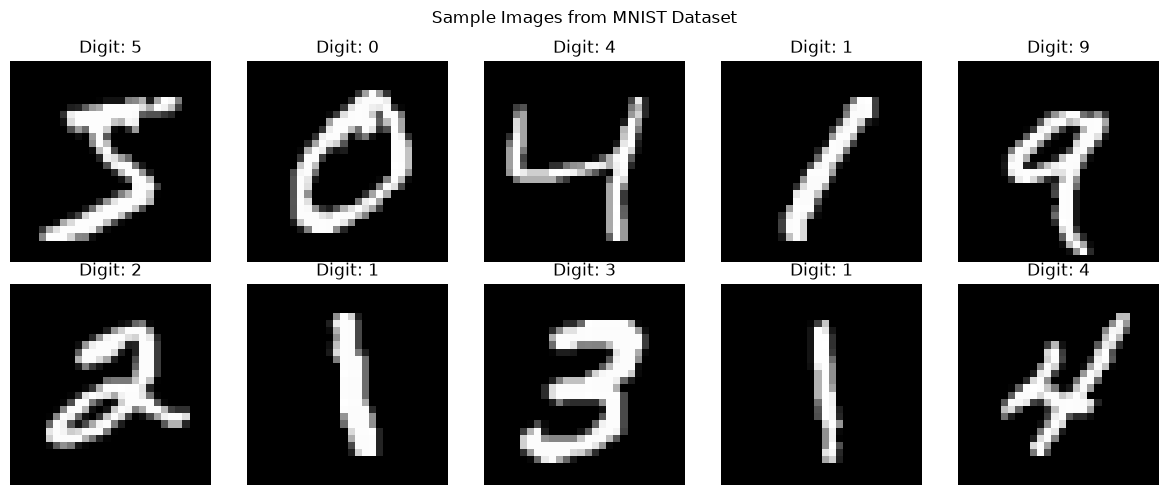

In [4]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Sample Images from MNIST Dataset")
plt.tight_layout()
plt.savefig("../screenshots/01_mnist_samples.png", dpi=150)
plt.show()

In [5]:
# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Convert labels into categorical format
y_train_cat = tf.keras.utils.to_categorical(y_train, 10)
y_test_cat = tf.keras.utils.to_categorical(y_test, 10)

# Display dataset information
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training labels shape:", y_train_cat.shape)
print("Testing labels shape:", y_test_cat.shape)

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

print("Preprocessing completed successfully!")

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Training labels shape: (60000, 10)
Testing labels shape: (10000, 10)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Preprocessing completed successfully!


In [6]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

# Create the neural network
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Train the model
history = model.fit(
    X_train,
    y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8786 - loss: 0.4166 - val_accuracy: 0.9618 - val_loss: 0.1355
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9487 - loss: 0.1726 - val_accuracy: 0.9695 - val_loss: 0.0996
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9613 - loss: 0.1289 - val_accuracy: 0.9752 - val_loss: 0.0865
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9686 - loss: 0.1040 - val_accuracy: 0.9767 - val_loss: 0.0787
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9732 - loss: 0.0866 - val_accuracy: 0.9787 - val_loss: 0.0740
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9756 - loss: 0.0771 - val_accuracy: 0.9775 - val_loss: 0.0754
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9780 - loss: 0.0688 - val_accuracy: 0.9772 - val_loss: 0.0769
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9804 - loss: 0.0614 - val_accuracy: 0.

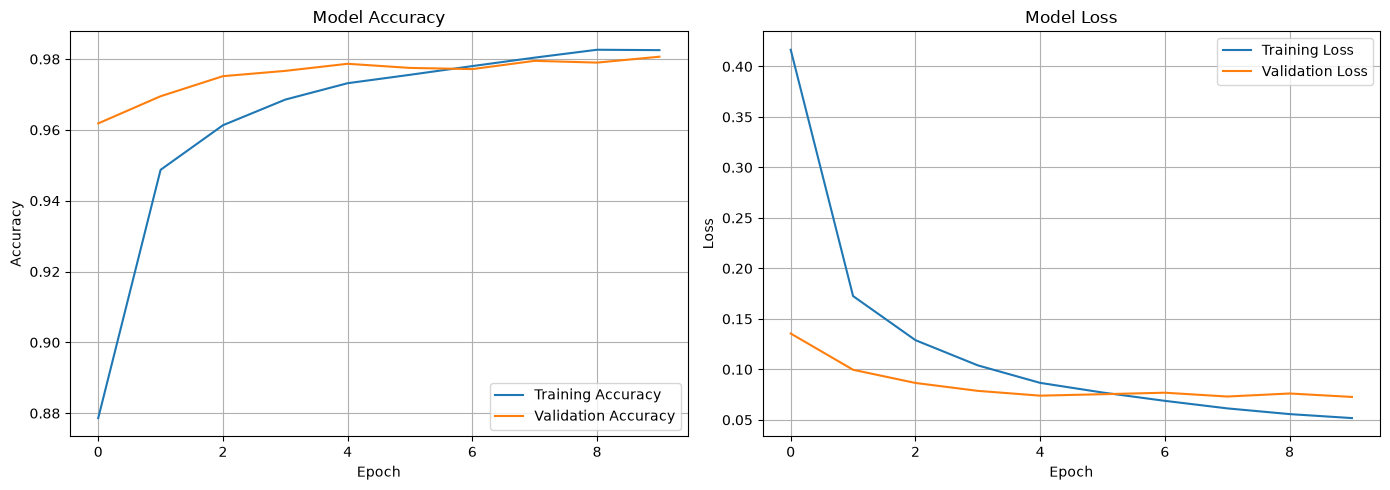

In [8]:
import matplotlib.pyplot as plt

# Create two graphs
plt.figure(figsize=(14, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

# Save visualization
plt.savefig("../screenshots/02_training_performance.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [9]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Evaluate model on test dataset
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_cat,
    verbose=0
)

# Generate predictions
y_pred_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

# Actual labels
y_true = y_test

# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted")
recall = recall_score(y_true, y_pred, average="weighted")
f1 = f1_score(y_true, y_pred, average="weighted")

print("TEST DATASET EVALUATION")
print("-----------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(y_true, y_pred))

TEST DATASET EVALUATION
-----------------------
Test Loss: 0.0718
Test Accuracy: 97.86%
Precision: 0.9787
Recall: 0.9786
F1-Score: 0.9786

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.98      0.98      1032
           3       0.98      0.98      0.98      1010
           4       0.99      0.96      0.97       982
           5       0.97      0.99      0.98       892
           6       0.98      0.97      0.98       958
           7       0.98      0.97      0.98      1028
           8       0.98      0.97      0.97       974
           9       0.96      0.99      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



<Figure size 1000x800 with 0 Axes>

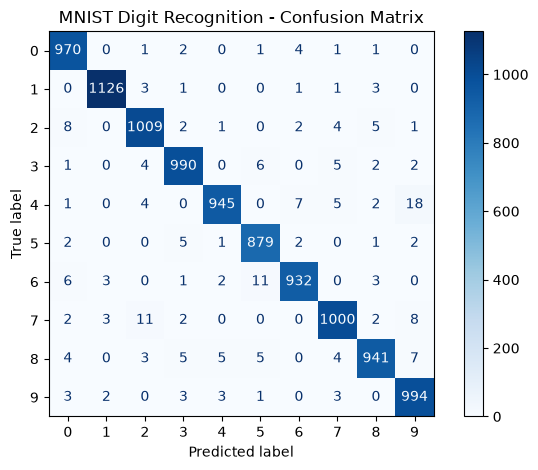

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display confusion matrix
plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("MNIST Digit Recognition - Confusion Matrix")
plt.tight_layout()

# Save visualization
plt.savefig(
    "../screenshots/03_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

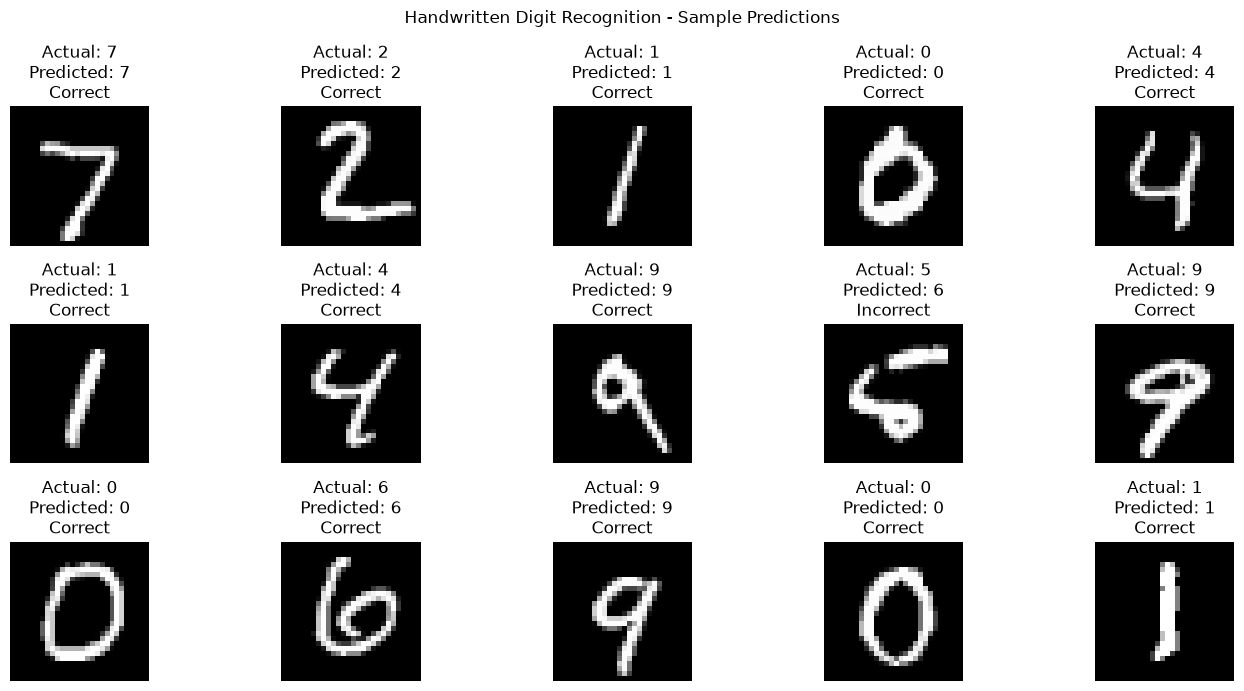

In [11]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(14, 7))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[i], cmap="gray")

    actual = y_true[i]
    predicted = y_pred[i]

    result = "Correct" if actual == predicted else "Incorrect"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}\n{result}"
    )
    plt.axis("off")

plt.suptitle("Handwritten Digit Recognition - Sample Predictions")
plt.tight_layout()

plt.savefig(
    "../screenshots/04_sample_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
# Save the trained model
model.save("../models/mnist_digit_recognition.keras")

print("Model saved successfully!")
print("Location: models/mnist_digit_recognition.keras")

Model saved successfully!
Location: models/mnist_digit_recognition.keras


Total test images: 10000
Correct predictions: 9786
Incorrect predictions: 214
Error rate: 2.14%


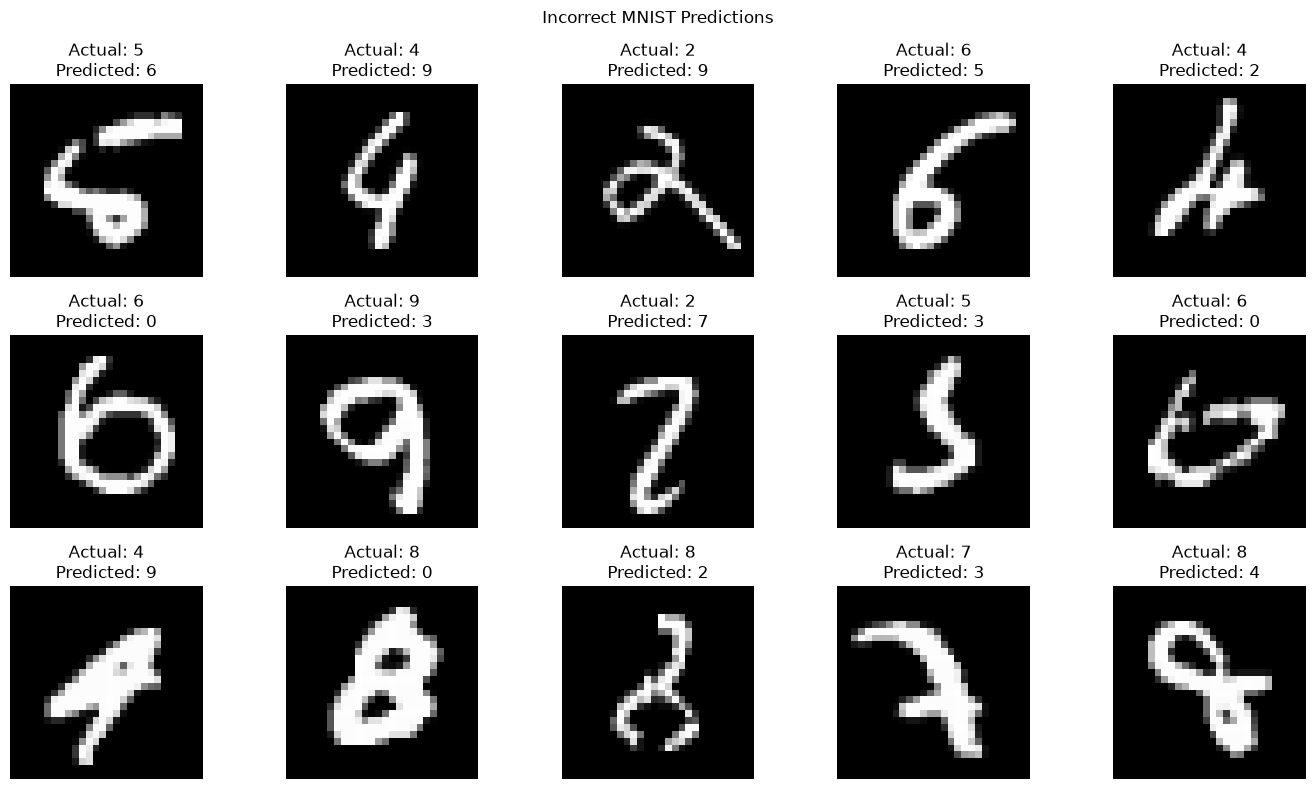

In [13]:
# Find incorrectly classified images
incorrect_indices = np.where(y_true != y_pred)[0]

print("Total test images:", len(y_true))
print("Correct predictions:", len(y_true) - len(incorrect_indices))
print("Incorrect predictions:", len(incorrect_indices))
print("Error rate:", f"{len(incorrect_indices) / len(y_true) * 100:.2f}%")

# Display up to 15 incorrect predictions
plt.figure(figsize=(14, 8))

for i, idx in enumerate(incorrect_indices[:15]):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[idx], cmap="gray")
    plt.title(
        f"Actual: {y_true[idx]}\nPredicted: {y_pred[idx]}"
    )
    plt.axis("off")

plt.suptitle("Incorrect MNIST Predictions")
plt.tight_layout()

plt.savefig(
    "../screenshots/05_incorrect_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
# Find the most confused digit pairs
cm_without_diagonal = cm.copy()
np.fill_diagonal(cm_without_diagonal, 0)

# Find the 10 largest confusion values
confusion_pairs = []

for actual_digit in range(10):
    for predicted_digit in range(10):
        if actual_digit != predicted_digit:
            confusion_pairs.append((
                cm_without_diagonal[actual_digit, predicted_digit],
                actual_digit,
                predicted_digit
            ))

confusion_pairs.sort(reverse=True)

print("TOP 10 MOST CONFUSED DIGIT PAIRS")
print("--------------------------------")

for count, actual, predicted in confusion_pairs[:10]:
    print(
        f"Actual digit {actual} predicted as {predicted}: "
        f"{count} times"
    )

TOP 10 MOST CONFUSED DIGIT PAIRS
--------------------------------
Actual digit 4 predicted as 9: 18 times
Actual digit 7 predicted as 2: 11 times
Actual digit 6 predicted as 5: 11 times
Actual digit 7 predicted as 9: 8 times
Actual digit 2 predicted as 0: 8 times
Actual digit 8 predicted as 9: 7 times
Actual digit 4 predicted as 6: 7 times
Actual digit 6 predicted as 0: 6 times
Actual digit 3 predicted as 5: 6 times
Actual digit 8 predicted as 5: 5 times


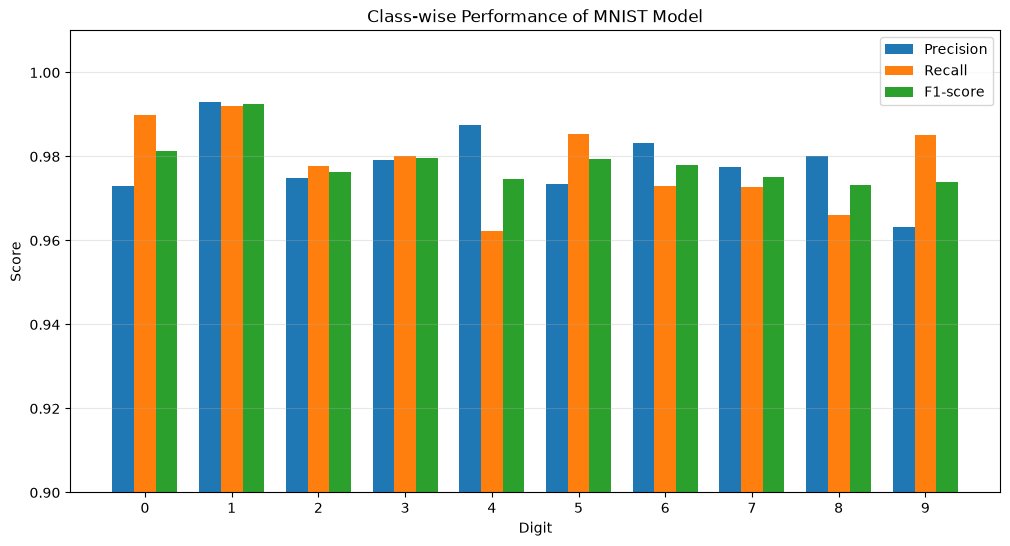

In [15]:
from sklearn.metrics import precision_recall_fscore_support
import numpy as np
import matplotlib.pyplot as plt

precision_class, recall_class, f1_class, _ = (
    precision_recall_fscore_support(
        y_true, y_pred,
        labels=range(10),
        zero_division=0
    )
)

digits = np.arange(10)
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(digits - width, precision_class, width, label="Precision")
plt.bar(digits, recall_class, width, label="Recall")
plt.bar(digits + width, f1_class, width, label="F1-score")

plt.xlabel("Digit")
plt.ylabel("Score")
plt.title("Class-wise Performance of MNIST Model")
plt.xticks(digits)
plt.ylim(0.90, 1.01)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    "../screenshots/06_classwise_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

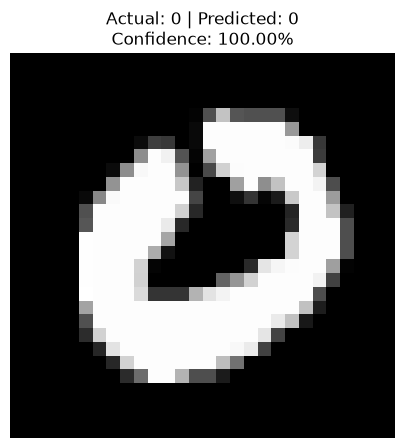

Saved model loaded successfully!
Actual digit: 0
Predicted digit: 0
Prediction confidence: 100.00%


In [18]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load the saved model
loaded_model = tf.keras.models.load_model(
    "../models/mnist_digit_recognition.keras"
)

# Select one test image
sample_index = 25
sample_image = X_test[sample_index]

# Predict using the loaded model
prediction = loaded_model.predict(
    np.expand_dims(sample_image, axis=0),
    verbose=0
)

predicted_digit = np.argmax(prediction)
confidence = np.max(prediction) * 100
actual_digit = y_test[sample_index]

# Display result
plt.figure(figsize=(5, 5))
plt.imshow(sample_image, cmap="gray")
plt.title(
    f"Actual: {actual_digit} | Predicted: {predicted_digit}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.savefig(
    "../screenshots/07_saved_model_prediction.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved model loaded successfully!")
print("Actual digit:", actual_digit)
print("Predicted digit:", predicted_digit)
print(f"Prediction confidence: {confidence:.2f}%")